In [5]:
import pandas as pd
from scipy.stats import f_oneway

# Load the dataset
df = pd.read_csv("traffic.csv")

# Create subsets for each weather condition
clouds = df[df['weather_main'] == 'Clouds']['traffic_volume']
clear = df[df['weather_main'] == 'Clear']['traffic_volume']
snow = df[df['weather_main'] == 'Snow']['traffic_volume']

# Perform ANOVA
f_statistic, p_value = f_oneway(clouds, clear, snow)

# Degrees of freedom
df_between = 2  # Number of weather conditions - 1
df_within = len(df) - 3  # Total number of observations - Number of weather conditions

# Output ANOVA table
anova_table = pd.DataFrame({
    ' ': ['Treatment', 'Error', 'Total'],
    'SS': [None, None, None],
    'df': [df_between, df_within, len(df) - 1],
    'MS': [None, None, None],
    'F': [f_statistic, None, None]
})

# Calculate SS and MS
ss_between = df_between * (clouds.var() + clear.var() + snow.var())
ss_within = sum((group - group.mean()).pow(2).sum() for group in [clouds, clear, snow])
ms_between = ss_between / df_between
ms_within = ss_within / df_within

# Fill in ANOVA table
anova_table.loc[0, 'SS'] = ss_between
anova_table.loc[1, 'SS'] = ss_within
anova_table.loc[2, 'SS'] = ss_between + ss_within

anova_table.loc[0, 'MS'] = ms_between
anova_table.loc[1, 'MS'] = ms_within

# Output the ANOVA table
print(anova_table)
print(f'F-statistic: {f_statistic}')
print(f'P-value: {p_value}')


                               SS     df               MS           F
0  Treatment      22385775.639642      2  11192887.819821  338.384375
1      Error   118348579728.59166  48201    2455313.78454         NaN
2      Total  118370965504.231308  48203             None         NaN
F-statistic: 338.384374796505
P-value: 3.994625891172287e-146


In [6]:
from scipy.stats import f

alpha = 0.05
df_between = 2  # 分子自由度
df_within = 48201  # 分母自由度

critical_value = f.ppf(1 - alpha, df_between, df_within)

print(f'F0.05({df_between}, {df_within}): {critical_value}')


F0.05(2, 48201): 2.9959184685434552


1 709, 659 713, 726 660, 645
2 668, 685 722, 740 692, 720
3 698, 685 666, 684 678, 750
4 698, 650 704, 666 686, 733

In [20]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

# Create a DataFrame with the given data
data = {
    'Brand1_Surface1': [709, 659],
    'Brand1_Surface2': [713, 726],
    'Brand1_Surface3': [660, 645],
    'Brand2_Surface1': [668, 685],
    'Brand2_Surface2': [722, 740], 
    'Brand2_Surface3': [692, 720],  
    'Brand3_Surface1': [698, 685],  
    'Brand3_Surface2': [666, 684],  
    'Brand3_Surface3': [678, 750],  
    'Brand4_Surface1': [698, 650], 
    'Brand4_Surface2': [704, 666],  
    'Brand4_Surface3': [686, 733]  
}

df = pd.DataFrame(data)

# Reset index to make 'Brand' a regular column
df.reset_index(inplace=True)

# Reshape the DataFrame for the analysis
df_melted = pd.melt(df, id_vars=['index'], var_name='Surface', value_name='Lifetime')

# Perform two-way ANOVA
formula = 'Lifetime ~ C(index) + C(Surface) + C(index):C(Surface)'
model = ols(formula, df_melted).fit()
anova_table = anova_lm(model)

# Output the ANOVA table
print(anova_table)


                       df        sum_sq      mean_sq    F  PR(>F)
C(index)              1.0  1.000417e+02   100.041667  0.0     NaN
C(Surface)           11.0  1.154546e+04  1049.587121  0.0     NaN
C(index):C(Surface)  11.0  7.862458e+03   714.768939  0.0     NaN
Residual              0.0  7.651421e-24          inf  NaN     NaN


c:\Users\HUAWEI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\stats\anova.py:138: RuntimeWarning: divide by zero encountered in scalar divide
  (model.ssr / model.df_resid))


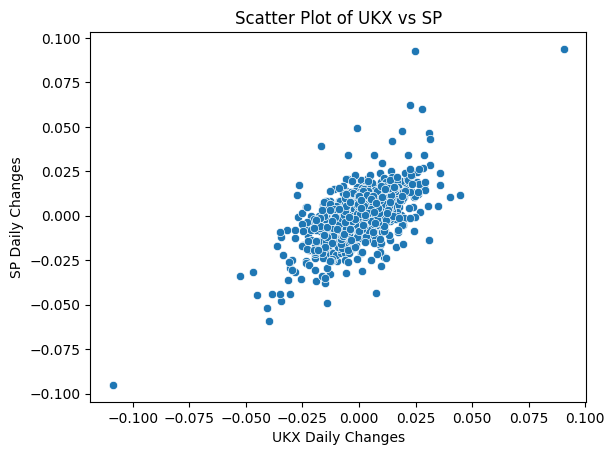

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the data
data = pd.read_csv('DailyChanges.csv')

# Plot the relationship
sns.scatterplot(x='UKX', y='SP', data=data)
plt.title('Scatter Plot of UKX vs SP')
plt.xlabel('UKX Daily Changes')
plt.ylabel('SP Daily Changes')
plt.show()


In [22]:
import statsmodels.api as sm

# Fit the simple linear regression model
X = sm.add_constant(data['UKX'])
model = sm.OLS(data['SP'], X).fit()

# Print model summary
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                     SP   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.375
Method:                 Least Squares   F-statistic:                     1065.
Date:                Sun, 10 Dec 2023   Prob (F-statistic):          1.94e-183
Time:                        14:16:45   Log-Likelihood:                 5938.2
No. Observations:                1778   AIC:                        -1.187e+04
Df Residuals:                    1776   BIC:                        -1.186e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0005      0.000      2.247      0.0

In [24]:
print(model.conf_int(0.05, cols=[0, 1]))


              0         1
const  0.000058  0.000857
UKX    0.605012  0.682377


c:\Users\HUAWEI\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\base\model.py:2220: FutureWarning: cols is deprecated and will be removed after 0.14 is released. cols only works when inputs are NumPy arrays and will fail when using pandas Series or DataFrames as input. Subsets of confidence intervals can be selected using slices of the full confidence interval array.
  warnings.warn(


In [23]:
print(model.t_test("UKX = 0"))


                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.6437      0.020     32.637      0.000       0.605       0.682


In [25]:
hypotheses = "UKX = 0.5"
print(model.t_test(hypotheses))


                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.6437      0.020      7.286      0.000       0.605       0.682


In [27]:
import statsmodels.api as sm

# Assuming 'model' is the fitted simple linear regression model

# Create a DataFrame with the UKX value set to 0
new_data = pd.DataFrame({'UKX': [0], 'const': 1})

# Calculate the predicted values
predicted_values = model.get_prediction(new_data).summary_frame(alpha=0.05)

# Extract the confidence intervals
confidence_intervals = predicted_values[['mean_ci_lower', 'mean_ci_upper']]

# Extract the prediction intervals
prediction_intervals = predicted_values[['obs_ci_lower', 'obs_ci_upper']]

# Print the intervals
print("95% Confidence Intervals:")
print(confidence_intervals)

print("\n95% Prediction Intervals:")
print(prediction_intervals)


95% Confidence Intervals:
   mean_ci_lower  mean_ci_upper
0       0.605012       0.682377

95% Prediction Intervals:
   obs_ci_lower  obs_ci_upper
0      0.601509      0.685879


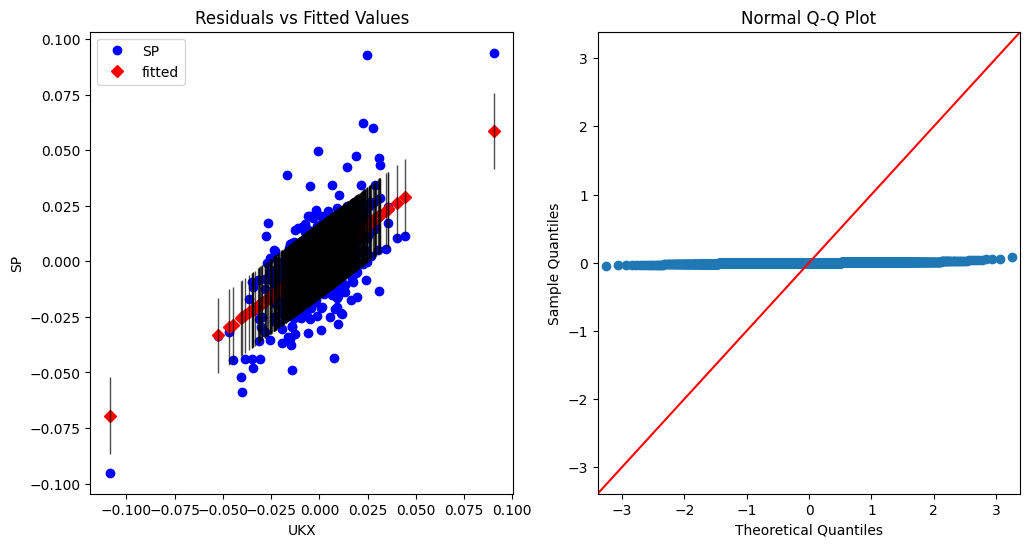

In [28]:
import statsmodels.graphics as smg

# Residuals vs Fitted Values plot
fig, axes = plt.subplots(figsize=(12, 6), nrows=1, ncols=2)
smg.regressionplots.plot_fit(model, 1, ax=axes[0])
axes[0].set_title('Residuals vs Fitted Values')

# Normal Q-Q plot
smg.gofplots.qqplot(model.resid, line='45', ax=axes[1])
axes[1].set_title('Normal Q-Q Plot')

plt.show()
